In [1]:
# IMPORTS
import caldis

import numpy as np
import matplotlib.pyplot as plt

from caldis.core.system import System
from caldis.components import FluidBoundary
from caldis.components import Compressor, Valve, ControlVolume, Turbine, SimpleHeater, TankConstV, SizingHX, TankConstP, RatingHX
from caldis.components.combustion.heater import SimpleHeater   # used here as a cooler
from caldis.fluids import CoolPropBackend
from caldis.solvers import solve                 # one-call workflow (DOF -> start -> solve)
from caldis.solvers.autostart import autostart, fix_port
from caldis.components import CombustionChamber
from CoolProp.CoolProp import PropsSI
from caldis.solvers.dynamic import simulate

In [2]:
# Modèle de design: le but = déterminer la surface de l'échangeur et condition de fonctionnement sur l'eau
be_air = CoolPropBackend('Air')
be_water = CoolPropBackend('Water')
p0 = 1e5
T0 = 273.15+15
T_w_in = 273.15+25
p_water = 80e5
V_tank_air = 2000
p_max = 16e5
p_min = 8e5

mdot = 1

source = FluidBoundary('source', backend = be_air, p=p0, T=T0)
comp = Compressor('comp', be_air, eta_is=0.85)
hex = SizingHX('hex', backend_hot=be_air, backend_cold=be_water, h_hot=1000, h_cold=1000, area_ratio_cold_to_hot=1/15)
sink_air = FluidBoundary('sink_air', backend = be_air, p=p_max)

source_water = FluidBoundary('source_water', backend = be_water, p=p_water, T=T_w_in)
sink_water = FluidBoundary('sink_water', backend = be_water)

sys = System('sys')
sys.add(source, comp, hex, sink_air, source_water, sink_water)

sys.connect(source.port, comp.inl)
sys.connect(comp.out, hex.hot_in)
sys.connect(hex.hot_out, sink_air.port)
sys.connect(source_water.port, hex.cold_in)
sys.connect(hex.cold_out, sink_water.port)

sys.add_constraint(lambda : comp.inl.mdot - mdot)
sys.add_constraint(lambda : hex.cold_out.T -273.15 - 250)
sys.add_constraint(lambda : hex.hot_out.T - T_w_in - 10)

autostart(sys)

sol_design = solve(sys)

✓ DOF: square (32 unknowns)
✓ start point: evaluable
⚠ 3 start-sanity warning(s):
   - hex: 'hot' channel is not hotter than 'cold' at start (hot 14/14°C vs cold 25/8°C) -- reversed hookup?
   - hex: temperature cross at start (dT1=5.5, dT2=-11.3 K)
   - hex: hot inlet/outlet nearly equal -> LMTD/flow degenerate
  (non-blocking.)
  direct Newton: ok (6 it, |F_scaled|=2.1e-10)
✓ SOLVED (|F_scaled|=2.1e-10)


In [3]:
mdot_w0 = hex.cold_in.mdot
hex_area_hot = hex.A_hot


In [4]:
# Modèle de simulation: le but = fixer la surface de l'échangeur et laisser calculer la température de l'eau chaude selon l'état de l'air compressé
be_air = CoolPropBackend('Air')
be_water = CoolPropBackend('Water')
p0 = 1e5
T0 = 273.15+15
T_w_in = 273.15+25
p_water = 50e5

p_max = 16e5
p_min = 16e5

mdot = 1

source = FluidBoundary('source', backend = be_air, p=p0, T=T0)
comp = Compressor('comp', be_air, eta_is=0.85)

# hex = SizingHX('hex', backend_hot=be_air, backend_cold=be_water, h_hot=1000, h_cold=1000, area_ratio_cold_to_hot=1/15)
# meme modèle que SizingHX mais avec A_hot fixé, donc pas de contrainte sur la température de sortie de l'air chaud
hex = RatingHX('hex', backend_hot=be_air, backend_cold=be_water, h_hot=1000, h_cold=1000, area_ratio_cold_to_hot=1/15, A_hot=hex_area_hot)

tank_air = TankConstV('tank_air', backend=be_air, V=V_tank_air, p_init=p_min, h_init=PropsSI('H','T',T0,'P',p_min,'Air'), C_wall=1e3, T_wall_init=T0, UA_wall=1e3)
cap = FluidBoundary('cap', backend = be_air, mdot=0.0)

source_water = FluidBoundary('source_water', backend = be_water, p=p_water, T=T_w_in, mdot=-mdot_w0)
sink_water = FluidBoundary('sink_water', backend = be_water)

sys = System('sys')
sys.add(source, comp, hex, tank_air, source_water, sink_water, cap)

sys.connect(source.port, comp.inl)
sys.connect(comp.out, hex.hot_in)
sys.connect(hex.hot_out, tank_air.inl)
sys.connect(tank_air.out, cap.port)

sys.connect(source_water.port, hex.cold_in)
sys.connect(hex.cold_out, sink_water.port)

sys.add_constraint(lambda : comp.inl.mdot - mdot, 'air flow rate')
# sys.add_constraint(lambda : hex.cold_out.T -273.15 - 250) # remplacé par la contrainte fixant A_hot de l'échangeur
# sys.add_constraint(lambda : hex.hot_out.T - T_w_in - 10, 'pinch') # remplacé par un débit eau fixé

autostart(sys)

sol = simulate(sys, t_end=3600*4, dt=1000, init=None)

PHYSICAL-VALIDITY WARNINGS (converged, but the solution may be non-physical):
  /!\ hex: hot outlet 24.4°C below cold inlet 25.0°C -- 2nd-law violation (single-zone NTU, constant cp, large span; split into exchangers in series)


In [5]:
# Le modèle précédent donne une solution non physique à cause de l'hypothèse cp constant qui n'est plus valide pour l'air et l'eau dont la température varie beaucoup
# Solution: discrétiser l'échangeur en K échangeurs en série, chacun avec cp constant

import numpy as np
from CoolProp.CoolProp import PropsSI
from caldis.core.system import System
from caldis.components import FluidBoundary, Compressor, SizingHX, RatingHX, TankConstV
from caldis.fluids import CoolPropBackend
from caldis.solvers import solve, simulate
from caldis.solvers.autostart import autostart

be_air, be_water = CoolPropBackend('Air'), CoolPropBackend('Water')
p0, T0      = 1e5, 273.15+15
T_w_in      = 273.15+25
p_water     = 50e5
p_tank      = 8e5
mdot_air    = 1.0
K           = 4                      # nombre d'echangeurs en serie

# ---------- (A) dimensionnement stationnaire : surface totale + debit d'eau ----------
src  = FluidBoundary('src', backend=be_air, p=p0, T=T0)
comp = Compressor('comp', be_air, eta_is=0.85)
hxd  = SizingHX('hxd', backend_hot=be_air, backend_cold=be_water,
                h_hot=1000, h_cold=1000, area_ratio_cold_to_hot=1/15)
sinkA = FluidBoundary('sinkA', backend=be_air, p=p_tank)
srcW  = FluidBoundary('srcW', backend=be_water, p=p_water, T=T_w_in)
sinkW = FluidBoundary('sinkW', backend=be_water)
d = System('design'); d.add(src, comp, hxd, sinkA, srcW, sinkW)
d.connect(src.port, comp.inl); d.connect(comp.out, hxd.hot_in)
d.connect(hxd.hot_out, sinkA.port)
d.connect(srcW.port, hxd.cold_in); d.connect(hxd.cold_out, sinkW.port)
d.add_constraint(lambda: comp.inl.mdot - mdot_air)
d.add_constraint(lambda: hxd.cold_out.T - (273.15+250))     # eau chaude visee
d.add_constraint(lambda: hxd.hot_out.T - (T_w_in+10))       # pincement cote air
autostart(d)
sold = solve(d, verbose=False)
A_total = hxd.A_hot
mdot_w0 = hxd.cold_in.mdot
print("design:", sold.success, "| A_hot total =", round(A_total,4), "| mdot_eau =", round(mdot_w0,4))

# ---------- (B) charge transitoire, K echangeurs en serie a contre-courant ----------
A_each = A_total / K
hx = [RatingHX(f'hx{i}', backend_hot=be_air, backend_cold=be_water,
               h_hot=1000, h_cold=1000, area_ratio_cold_to_hot=1/15, A_hot=A_each)
      for i in range(K)]

source = FluidBoundary('source', backend=be_air, p=p0, T=T0)
comp2  = Compressor('comp', be_air, eta_is=0.85)
tank   = TankConstV('tank', backend=be_air, V=V_tank_air, p_init=p_tank,
                    h_init=PropsSI('H','T',T0,'P',p_tank,'Air'),
                    C_wall=1e8, T_wall_init=T0, UA_wall=1e5)      # paroi grande mais FINIE
cap    = FluidBoundary('cap', backend=be_air, mdot=0.0)
sw     = FluidBoundary('sw', backend=be_water, p=p_water, T=T_w_in, mdot=-mdot_w0)  # debit eau impose
swk    = FluidBoundary('swk', backend=be_water)

s = System('charge_series'); s.add(source, comp2, tank, cap, sw, swk, *hx)
# air (chaud) en serie : comp -> hx0 -> hx1 -> ... -> tank
s.connect(source.port, comp2.inl); s.connect(comp2.out, hx[0].hot_in)
for i in range(K-1): s.connect(hx[i].hot_out, hx[i+1].hot_in)
s.connect(hx[K-1].hot_out, tank.inl); s.connect(tank.out, cap.port)
# eau (froid) a CONTRE-COURANT : sw -> hx[K-1] -> ... -> hx0 -> swk
s.connect(sw.port, hx[K-1].cold_in)
for i in range(K-1, 0, -1): s.connect(hx[i].cold_out, hx[i-1].cold_in)
s.connect(hx[0].cold_out, swk.port)
s.add_constraint(lambda: comp2.inl.mdot - mdot_air)

autostart(s)

sol = simulate(s, t_end=3600*4, dt=1000, init=None)


design: True | A_hot total = 202.6495 | mdot_eau = 0.2638


profils (etat final) :
  hx0: air   392.3 ->   257.3 C   |   eau  221.6 ->  263.9 C
  hx1: air   257.3 ->   166.9 C   |   eau  141.2 ->  221.6 C
  hx2: air   166.9 ->    97.1 C   |   eau   76.9 ->  141.2 C
  hx3: air    97.1 ->    41.2 C   |   eau   25.0 ->   76.9 C
sortie AIR globale =  41.2 C  (doit etre > 25 C : entree eau)
sortie EAU globale = 263.9 C


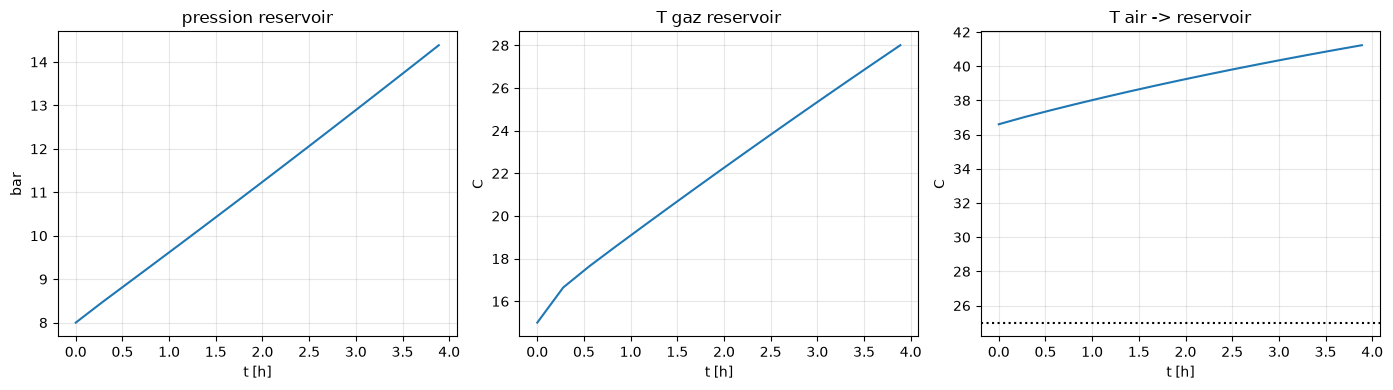

In [ ]:
# vérification des résultats
print("profils (etat final) :")
for i in range(K):
    Ta_in  = be_air.T(hx[i].hot_in.p,   hx[i].hot_in.h)   - 273.15
    Ta_out = be_air.T(hx[i].hot_out.p,  hx[i].hot_out.h)  - 273.15
    Tw_in  = be_water.T(hx[i].cold_in.p, hx[i].cold_in.h) - 273.15
    Tw_out = be_water.T(hx[i].cold_out.p,hx[i].cold_out.h)- 273.15
    print(f"  hx{i}: air {Ta_in:7.1f} -> {Ta_out:7.1f} C   |   eau {Tw_in:6.1f} -> {Tw_out:6.1f} C")

Ta_global = be_air.T(hx[K-1].hot_out.p, hx[K-1].hot_out.h) - 273.15
Tw_global = be_water.T(hx[0].cold_out.p, hx[0].cold_out.h) - 273.15
print(f"sortie AIR globale = {Ta_global:5.1f} C  (doit etre > 25 C : entree eau)")
print(f"sortie EAU globale = {Tw_global:5.1f} C")

# --- series temporelles du reservoir ---
import numpy as np, matplotlib.pyplot as plt
t_h = sol.time/3600.0
p_tank_t = sol.tank.fluid.p/1e5          # tableau
T_tank_t = sol.tank.T_fluid - 273.15     # TankConstV expose T_fluid
# temperature air en sortie du dernier HX (-> reservoir) au cours du temps
pb, hb = sol["hx%d.hot_out.p" % (K-1)], sol["hx%d.hot_out.h" % (K-1)]
Ta_out_t = np.array([be_air.T(p, h) for p, h in zip(pb, hb)]) - 273.15

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(t_h, p_tank_t);  ax[0].set_title("pression reservoir");  ax[0].set_xlabel("t [h]"); ax[0].set_ylabel("bar"); ax[0].grid(alpha=.3)
ax[1].plot(t_h, T_tank_t);  ax[1].set_title("T gaz reservoir");     ax[1].set_xlabel("t [h]"); ax[1].set_ylabel("C");   ax[1].grid(alpha=.3)
ax[2].plot(t_h, Ta_out_t);  ax[2].axhline(25, ls=":", c="k"); ax[2].set_title("T air -> reservoir"); ax[2].set_xlabel("t [h]"); ax[2].set_ylabel("C"); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

transient OK  |  n points = 15


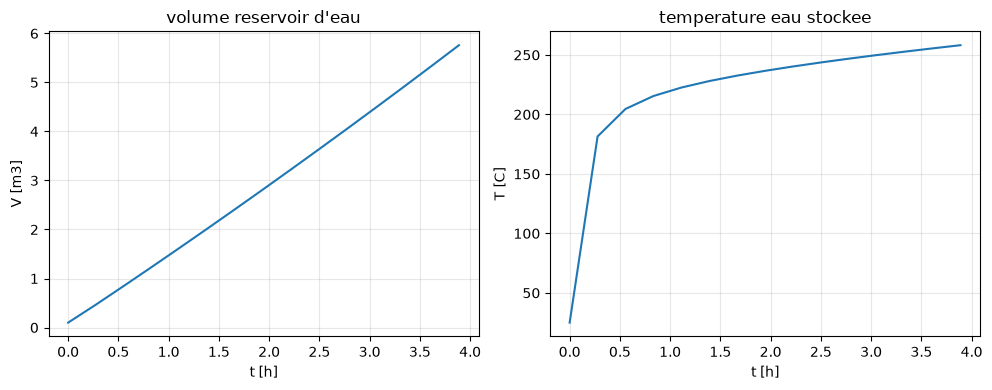

volume: 0.100 -> 5.759 m3   |   T eau: 25.0 -> 258.2 C


In [7]:
# ---------- (B) charge transitoire, K echangeurs en serie + reservoir d'eau chaude ----------
A_each = A_total / K
hx = [RatingHX(f'hx{i}', backend_hot=be_air, backend_cold=be_water,
               h_hot=1000, h_cold=1000, area_ratio_cold_to_hot=1/15, A_hot=A_each)
      for i in range(K)]

source = FluidBoundary('source', backend=be_air, p=p0, T=T0)
comp2  = Compressor('comp', be_air, eta_is=0.85)
tank   = TankConstV('tank', backend=be_air, V=V_tank_air, p_init=p_tank,
                    h_init=PropsSI('H','T',T0,'P',p_tank,'Air'),
                    C_wall=1e8, T_wall_init=T0, UA_wall=1e5)
cap    = FluidBoundary('cap', backend=be_air, mdot=0.0)

# source d'eau : debit + temperature imposes, PAS de pression (ancree par le reservoir)
# débit à ajouter pour ne pas évaporer l'eau
sw     = FluidBoundary('sw', backend=be_water, T=T_w_in, mdot=-mdot_w0*1.2)

# reservoir d'eau chaude : p constante, volume variable, accumulateur (cul-de-sac)
h_w_cold = PropsSI('H','T',T_w_in,'P',p_water,'Water')
tank_water = TankConstP('tank_water', backend=be_water, p=p_water,
                        h_init=h_w_cold, V_init=0.1,
                        C_wall=1e3, T_wall_init=T_w_in, UA_wall=0.0)   # paroi decouplee
cap_w  = FluidBoundary('cap_w', backend=be_water, mdot=0.0)

s = System('charge_series'); s.add(source, comp2, tank, cap, sw, tank_water, cap_w, *hx)
# air (chaud) en serie : comp -> hx0 -> ... -> tank
s.connect(source.port, comp2.inl); s.connect(comp2.out, hx[0].hot_in)
for i in range(K-1): s.connect(hx[i].hot_out, hx[i+1].hot_in)
s.connect(hx[K-1].hot_out, tank.inl); s.connect(tank.out, cap.port)
# eau (froid) a contre-courant : sw -> hx[K-1] -> ... -> hx0 -> tank_water -> cap_w
s.connect(sw.port, hx[K-1].cold_in)
for i in range(K-1, 0, -1): s.connect(hx[i].cold_out, hx[i-1].cold_in)
s.connect(hx[0].cold_out, tank_water.inl)
s.connect(tank_water.out, cap_w.port)
s.add_constraint(lambda: comp2.inl.mdot - mdot_air)

autostart(s)

sol = simulate(s, t_end=3600*4, dt=1000, init=None)
print("transient OK  |  n points =", len(sol.time))

# --- evolution du reservoir d'eau : volume et temperature ---
import matplotlib.pyplot as plt
t_h = sol.time/3600.0
V_w = sol.tank_water.V                 # m3 (volume variable)
T_w = sol.tank_water.T_fluid - 273.15  # C
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(t_h, V_w); ax[0].set_title("volume reservoir d'eau"); ax[0].set_xlabel("t [h]"); ax[0].set_ylabel("V [m3]"); ax[0].grid(alpha=.3)
ax[1].plot(t_h, T_w); ax[1].set_title("temperature eau stockee"); ax[1].set_xlabel("t [h]"); ax[1].set_ylabel("T [C]"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"volume: {V_w[0]:.3f} -> {V_w[-1]:.3f} m3   |   T eau: {T_w[0]:.1f} -> {T_w[-1]:.1f} C")

T_sat(eau a 50 bar) = 263.9 C
masse eau : 99.9 -> 4532.5 kg   |   T eau : 25.0 -> 258.2 C


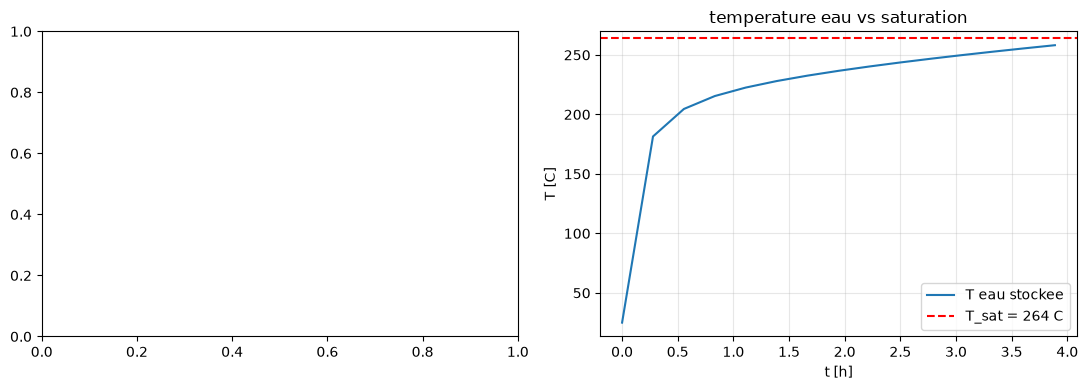

In [8]:
import numpy as np, matplotlib.pyplot as plt
from CoolProp.CoolProp import PropsSI

t_h   = sol.time/3600.0
rho_w = sol.tank_water.fluid.rho           # kg/m3 (serie)
V_w   = sol.tank_water.fluid.V             # m3    (volume variable)
M_w   = rho_w * V_w                         # masse d'eau stockee [kg]
T_w   = sol.tank_water.T_fluid - 273.15     # C

# temperature de saturation de l'eau a p_water
Tsat = PropsSI('T', 'P', p_water, 'Q', 0, 'Water') - 273.15
print(f"T_sat(eau a {p_water/1e5:.0f} bar) = {Tsat:.1f} C")
print(f"masse eau : {M_w[0]:.1f} -> {M_w[-1]:.1f} kg   |   T eau : {T_w[0]:.1f} -> {T_w[-1]:.1f} C")

# verification bilan de masse : M(t) = M0 + mdot_eau * t  (entree constante, sortie nulle)
M0 = PropsSI('D','T',T_w_in,'P',p_water,'Water') * 0.1     # V_init = 0.1 m3
M_theo = M0 + mdot_w0 * sol.time

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[1].plot(t_h, T_w, label="T eau stockee")
ax[1].axhline(Tsat, ls="--", c="r", label=f"T_sat = {Tsat:.0f} C")
ax[1].set_title("temperature eau vs saturation"); ax[1].set_xlabel("t [h]"); ax[1].set_ylabel("T [C]")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()